<a href="https://colab.research.google.com/github/Kabuyefwe12/Ass1/blob/main/Loan_Approval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 73 (292.00 B)

 Trainable params: 73 (292.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.3333 - loss: 41.8181
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.3333 - loss: 40.0836
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.3333 - loss: 38.3520
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.3333 - loss: 36.6232
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.3333 - loss: 34.8972
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.3333 - loss: 33.1741
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.3333 - loss: 31.4539
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.3333 - loss: 29.7367
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.3333 - loss: 28.0225
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.3333 - loss: 26.3112
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.3333 - loss: 24.6029
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.

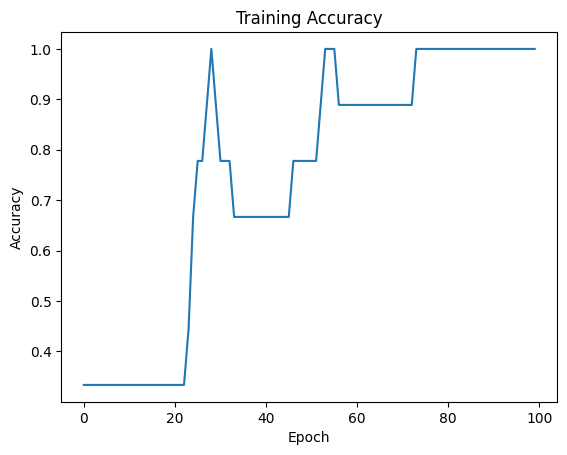

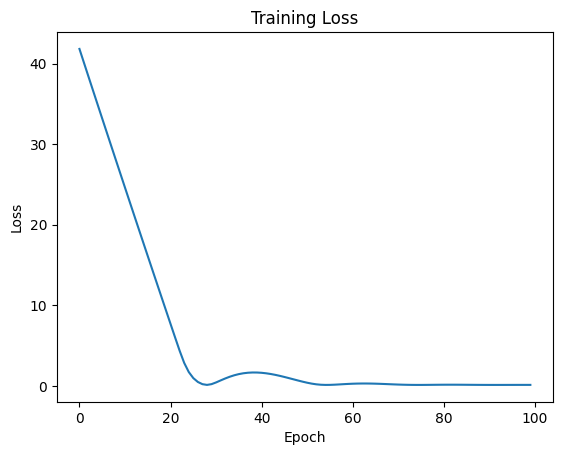

In [1]:
# ====== LOAN APPROVAL PREDICTOR ======

# 1. Import libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# 2. Create input data
# Columns: [Annual Income ($k), Credit Score, Years Employed]
X = np.array([
    [30, 580, 1],
    [45, 620, 2],
    [50, 650, 3],
    [60, 700, 4],
    [75, 720, 5],
    [90, 750, 6],
    [110, 780, 8],
    [120, 810, 10],
    [25, 520, 0],
    [35, 590, 1],
    [80, 710, 4],
    [100, 760, 7]
])

# 3. Create target values (0 = Denied, 1 = Approved)
y = np.array([0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1])

# 4. Split data into training and testing sets (75% train, 25% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# 5. Build the neural network architecture
model = Sequential()
model.add(Dense(8, activation="relu", input_shape=(3,)))
model.add(Dense(4, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

# 6. Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# 7. Display architecture summary
model.summary()

# 8. Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    verbose=1
)

# 9. Evaluate the model on test data
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("\nTest Loss:", loss)
print("Test Accuracy:", accuracy)

# 10. Predict a new applicant (e.g., $85k income, 730 credit score, 5 years employed)
new_applicant = np.array([[85, 730, 5]])
prediction = model.predict(new_applicant)
print("Prediction probability:", prediction[0][0])

# 11. Convert probability to class (Approved/Denied)
if prediction[0][0] >= 0.5:
    print("Prediction: LOAN APPROVED")
else:
    print("Prediction: LOAN DENIED")

# 12. Plot training accuracy graph
plt.plot(history.history["accuracy"])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

# 13. Plot training loss graph
plt.plot(history.history["loss"])
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()